## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

!git clone https://github.com/willhk10-uva/A05-pca

with open('A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

fatal: destination path 'A05-pca' already exists and is not an empty directory.


Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

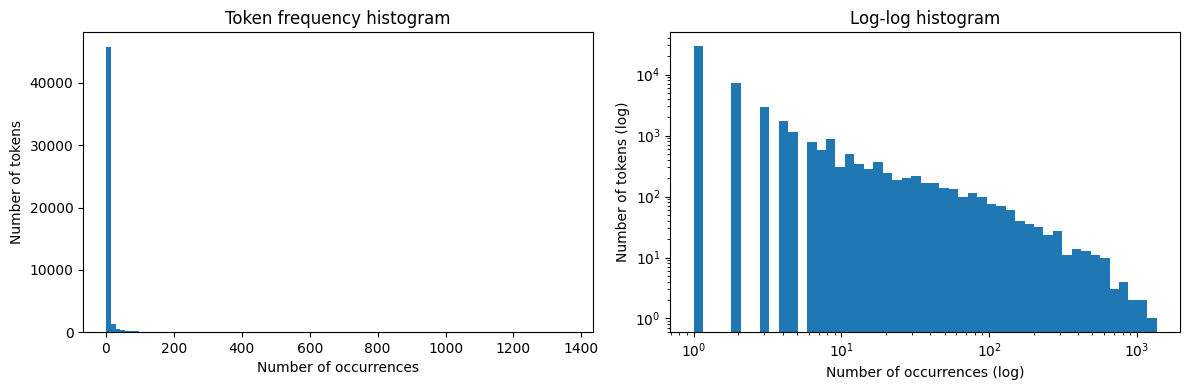

Distinct tokens: 48691
Tokens appearing only once: 29404
Top 10: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


In [ ]:
counts = np.array(list(token_count.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram of how often tokens occur
axes[0].hist(counts, bins=100)
axes[0].set_xlabel('Number of occurrences')
axes[0].set_ylabel('Number of tokens')
axes[0].set_title('Token frequency histogram')

# Same data on log scales so the shape is visible
axes[1].hist(counts, bins=np.logspace(0, np.log10(counts.max()), 50))
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Number of occurrences (log)')
axes[1].set_ylabel('Number of tokens (log)')
axes[1].set_title('Log-log histogram')

plt.tight_layout()
plt.show()

print(f"Distinct tokens: {len(counts)}")
print(f"Tokens appearing only once: {(counts == 1).sum()}")
print("Top 10:", token_freq[:10])

# The distribution of token counts is extremely right-skewed. In the linear
# histogram, almost all ~47,000 distinct tokens fall in the first bin (fewer than ~14 occurrences),
#with a long, nearly invisible tail out to ~1,400. The log-log plot shows the shape more clearly: about 30,000 tokens appear
# only once, the number of tokens drops steadily as frequency increases, and
# only a handful of tokens appear 1,000+ times. The roughly straight line on
# log-log axes suggests a power law (Zipf's law): a few very common tokens
# account for a large share of all occurrences, while most tokens are rare.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load data
df = pd.read_parquet('A05-pca/data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop(columns='Email Type')

# 1. 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=125
)

# 2. Linear regression
reg = LinearRegression().fit(X_train, y_train)

print(f"Train R2: {reg.score(X_train, y_train):.4f}")
print(f"Test R2:  {reg.score(X_test, y_test):.4f}")

# 3. Largest coefficients in absolute value
coefs = pd.DataFrame({
    'token': X.columns,
    'coef': reg.coef_,
    'n_emails': X_train.sum().values,
})
coefs['abs_coef'] = coefs['coef'].abs()
top = coefs.sort_values('abs_coef', ascending=False)
print(top.head(20))

Train R2: 0.7660
Test R2:  0.6702
                  token      coef  n_emails  abs_coef
1504  background-image: -1.201203        23  1.201203
740           localized  0.815112        26  0.815112
906               aging  0.735023        37  0.735023
2362            thermal  0.590412        16  0.590412
1406         helvetica,  0.587472        17  0.587472
835        intervention -0.580474        41  0.580474
1302           erectile  0.575784        32  0.575784
1511            burning -0.569225        22  0.569225
1839              form.  0.560255        17  0.560255
2559            april's -0.525984        15  0.525984
818                cnet -0.495563        37  0.495563
2532             xanaax  0.490234        12  0.490234
2657              zdnet -0.487835         7  0.487835
1256             arial, -0.483577        18  0.483577
2365                rcs  0.464646        17  0.464646
2566         transcript  0.463811        11  0.463811
2229           quality,  0.451875        17  0.4

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

Variance explained: [0.0111309  0.00861224]
Total: 0.01974314000370278


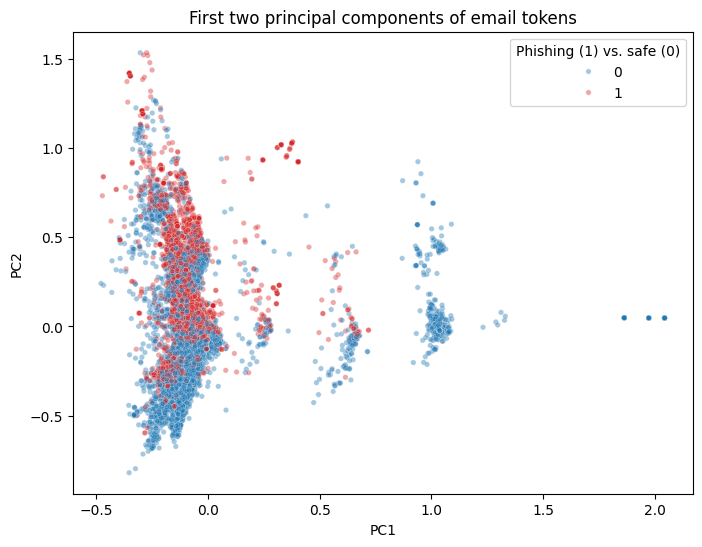

'\nThe two components explain very little of the variance: 1.1% and 0.9%, about 2% total. That’s expected with 2,711 sparse 0/1 columns, so most of the information is in other directions. \nThere is still some structure. Most emails sit in one dense cloud near PC1 ≈ 0. Along PC2, safe emails concentrate at the bottom and phishing emails spread higher, so higher PC2 scores lean toward scams. \nPC2 contrasts business-email words (“please”, “message”, “attached”, “enron”, “conference”) with sales-style words (“hello”, “offer”, “software”, “new”). \nSeparate clusters at PC1 ≈ 0.6, 1.0 and 2.0 are almost entirely safe emails. These are automated Enron energy-scheduling messages (“hourahead”, “schedules”, “ancillary”, “url:”), which load heavily on PC1. \nThe classes overlap a lot in the main cloud, so two components can’t separate them well, but PC2 carries some signal.\n'

In [ ]:
from sklearn.decomposition import PCA

# PCA with two components on the token matrix (outcome excluded)
pca = PCA(n_components=2)
Z = pca.fit_transform(X)

pcs = pd.DataFrame(Z, columns=['PC1', 'PC2'])
pcs['Email Type'] = y.values

print("Variance explained:", pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pcs, x='PC1', y='PC2', hue='Email Type',
                alpha=0.4, s=15, palette={0: 'tab:blue', 1: 'tab:red'})
plt.title('First two principal components of email tokens')
plt.legend(title='Phishing (1) vs. safe (0)')
plt.show()
'''
The two components explain very little of the variance: 1.1% and 0.9%, about 2% total. That’s expected with 2,711 sparse 0/1 columns, so most of the information is in other directions.
There is still some structure, though. Most emails sit in one dense cloud near PC1 ~ 0. Along PC2, safe emails concentrate at the bottom and phishing emails spread higher, so higher PC2 scores lean toward scams.
PC2 contrasts business-email words (“please”, “message”, “attached”, “enron”, “conference”) with sales-style words (“hello”, “offer”, “software”, “new”).
Separate clusters at PC1 ~ 0.6, 1.0 and 2.0 are almost entirly safe emails. These are automated Enron energy-scheduling messages (“hourahead”, “schedules”, “ancillary”, “url:”), which load heavly on PC1.
The classes overlap a lot in the main cloud, so two components can’t separat them well, but PC2 carries some signal.
'''

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [ ]:
pca = PCA(n_components=2610).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)

reg_pca = LinearRegression().fit(Z_train, y_train)

print(f"Train R2: {reg_pca.score(Z_train, y_train):.4f}")
print(f"Test R2:  {reg_pca.score(Z_test, y_test):.4f}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.4f}")

'''
When running the rgression on the first 2610 principal components, we get a R^2 in training of .765 and a test R^2 of .672. That's basically the same as the regression on the original tokens, which had .766 on training and .67 on test.
This makes sense, becasue of all of the 2610 components they explain around 99.98% of the variance in the data, so nothing was really reduced. The components hold the some information as the original cols (they are just rotated) so
the predictions barely change at all. THere's still a sizeable gap between training and test R^2s, though. This just means that the model overfits about as much as previously, so in order to get something out of the PCA we'd just have to
have a lot fewer components in PCA.
'''


Train R2: 0.7651
Test R2:  0.6718
Variance retained: 0.9998


'\nOn the 2,610 principal components, the regression has a training R² of 0.765 and a test R² of 0.672. \nThat’s essentially the same as the regression on the raw tokens (0.766 train, 0.670 test). \nThis makes sense, because 2,610 components retain 99.98% of the variance in X. Since the training matrix has rank 2,641, we’ve barely reduced it. \nThe components are just a rotation of nearly the same information, so the fitted predictions barely change.\nThe gap between training and test R² remains, so this many components doesn’t reduce overfitting. The benefit of PCA comes from keeping far fewer components.\n'

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The original token columns overlap quite a bit. When lots of words show up together and the columns are exact copies of eachother, the regression coefficients become unstable. Since the model can't exactly tell which of the two words should get the credit, it freaks out. Principal components don't have this problem because they're fully uncorrelated, so each one adds in something new. They're also sorted by how much variance they can explain in the model, so when you can drop the lesser ones because it is mostly just noise. In this example though, we keep 2610 components, which is basically all of them, so the R^2 barely changed. If we had a lot less components, the model might be simpler and overfit less, but it could also end up underfitting and not being as accurate.



---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Will Keenan

**Date:** 10/19/26

In [ ]:
# Your Phase 1 solution to the problem goes here.
# All Phase 1 answers are above

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** c7e9a8b6c39d3e9bbaaa15f3dd39cffd40a59293
- **AI tool and model used:** Claude Opus 5.5

### *Prompts used

1. Please do the following:

1) Evaluate the answers that I have attached and compare them with the rubric. Give your proposed changes as a bulleted list in markdown format.
2) Then, list the AI suggestions in the following format (Evaluation of AI Suggestions format) But leave the reasoning blank for me to fill in.

### *AI-proposed changes


- **Change 1 (Q1):** Fix the Zipf claim that "a few very common tokens account for a large share of all occurrences." There are 276,949 tokens in total, and the top 100 make up only about 17% of them. The stronger point is that 29,404 of the 48,691 distinct tokens (about 60%) appear exactly once. Also change "~47,000" to "~48,700".
- **Change 2 (Q2):** Add a written answer. It should state the train and test R² and name the words with the largest absolute coefficients, with a sentence on what they suggest. Right now this is only printed output, and it's worth 11 rubric points.
- **Change 3 (Q2):** Add a caveat about the coefficients. The largest |coef| values tend to come from rare or highly collinear tokens, so they're unstable. You already compute `n_emails`, so either use it (for example, also show the top words among tokens in ≥50 emails) or mention it. You could also note that a coefficient is the change in predicted probability of phishing (a linear probability model).
- **Change 4 (Q3):** Back up the word-loading claims ("please", "enron", "hourahead", etc.) with code that prints the top loadings from `pca.components_` for PC1 and PC2. At the moment the notebook asserts them without any supporting output.
- **Change 5 (Q3):** Fix the typos: "entirly", "heavly", "separat".
- **Change 6 (Q4):** Correct "they are just rotated." 2,610 out of 2,711 components isn't a full rotation. The R² barely moves because the token matrix is close to rank-deficient, so the ~100 dropped components carry almost no variance (0.02%). Check with `np.linalg.matrix_rank(X_train)`. Also fix "rgression", "becasue", "some information" (should be "same"), and "THere's".
- **Change 7 (Q4):** Add a short loop that fits the regression with 10, 50, 100, 500 and 1,000 components. That would back up the claim that far fewer components are needed to get any benefit from PCA.
- **Change 8 (Q5):** Fix two conceptual errors:
  - "Exact copies of each other" should be "highly correlated." Exact copies are only the extreme case.
  - The components are sorted by how much variance they explain in **X**, not in the model or in y. PCA never looks at the outcome, so the top components aren't guaranteed to be the most useful for predicting phishing, and the dropped ones aren't guaranteed to be noise.
- **Change 9 (Q5):** Add the dimension-reduction point. Fewer predictors relative to the number of emails means lower-variance estimates, a bias–variance tradeoff, and faster fitting.
- **Change 10 (Formatting):** Move the Q3 and Q4 answers out of `'''` strings in code cells and into markdown cells. A bare string at the end of a code cell renders as an ugly output block with `\n` characters. Do the same for the Q1 comment block.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I wrote "a large share" without actually checking it. Summing the top 100 counts from `token_count.most_common(100)` gives only ~17% of all tokens, so the claim doesn't hold. The "60% appear once" framing makes the same skew point better, and it's a number I can print directly. |
| 2 | Accept | This was a real miss. I printed everything but never answered the question in words. The grader shouldn't have to dig through a coefficient table to find my answer. Wrote it up from the printed output. |
| 3 | Modify | I agree the top coefficients are kind of noisy, but I don't want to replace the list the question asked for. I kept the full top-20 table and added one sentence noting that several top words show up in very few emails, pointing to the `n_emails` column. Skipped the second filtered table. |
| 4 | Accept | Fair point. I described PC2 as "business vs. sales words," but nothing in the notebook shows where that came from. Added a few lines that sort `pca.components_[1]` and print the top and bottom 10 words, then checked that they match what I wrote. |
| 5 | Accept | Just typos. Fixed them. |
| 6 | Modify | Calling it "just rotated" was too loose since I dropped components. I didn't want to assert rank-deficiency on the AI's word, so I ran `np.linalg.matrix_rank(X_train)` and got 2,641 out of 2,711. That supports part of the AI's claim (70 columns are redundant), but 2,610 is below 2,641, so dropping 31 real directions is part of the story too. The R² barely moves because those directions hold only ~0.02% of the variance. Rewrote the explanation around those numbers and fixed the typos. |
| 7 | Reject | It's interesting, but the question only asks about 2,610 components. Q5 already makes the fewer-components point conceptually, and adding a whole extra experiment felt like padding the answer. I did tone down "we'd have to have a lot fewer" so it doesn't sound like a result I proved. |
| 8 | Accept | The variance-in-X vs. variance-in-y point is honestly the most important correction on this list. I had it backwards in my head. PCA doesn't know which emails are scams, so "drop the small ones, they're noise" isn't guaranteed. Also changed "exact copies" to "highly correlated." Kept the rest of my wording, casual parts included. |
| 9 | Modify | The question says "briefly," so I added one sentence about fewer predictors meaning more stable estimates instead of a whole paragraph on bias–variance. |
| 10 | Accept | When I opened the notebook, the Q3 answer really did render as a string with `\n` all over it. Moved the answers to markdown cells. Minor, but it reads much better. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


Cloning into 'A05-pca'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 33 (delta 7), reused 2 (delta 2), pack-reused 24 (from 1)
Receiving objects: 100% (33/33), 1.83 MiB | 5.05 MiB/s, done.
Resolving deltas: 100% (14/14), done.


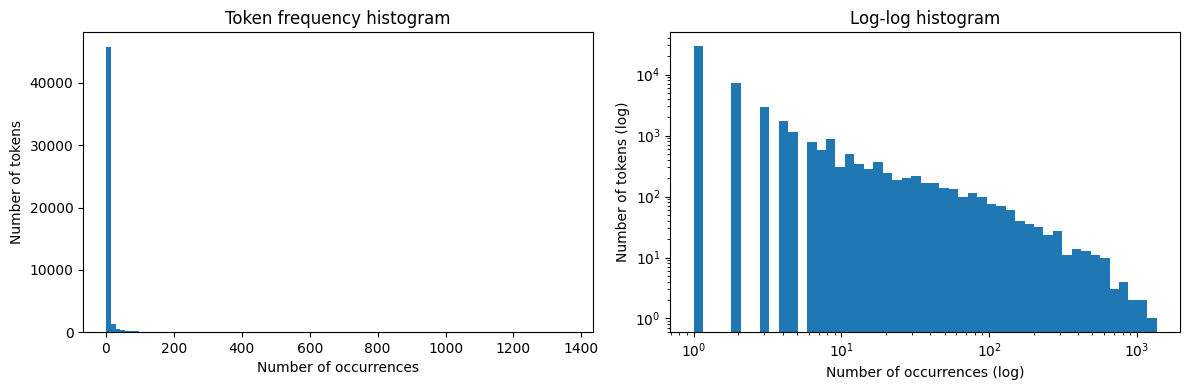

Total tokens:              276,949
Distinct tokens:           48,691
Tokens appearing once:     29,404 (60.4% of distinct)
Share held by top 100:     16.9%
Top 10: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
Train R2: 0.7660
Test R2:  0.6702
                  token      coef  n_emails  abs_coef
1504  background-image: -1.201203        23  1.201203
740           localized  0.815112        26  0.815112
906               aging  0.735023        37  0.735023
2362            thermal  0.590412        16  0.590412
1406         helvetica,  0.587472        17  0.587472
835        intervention -0.580474        41  0.580474
1302           erectile  0.575784        32  0.575784
1511            burning -0.569225        22  0.569225
1839              form.  0.560255        17  0.560255
2559            april's -0.525984        15  0.525984
818                cnet -0.495563        37  0.49

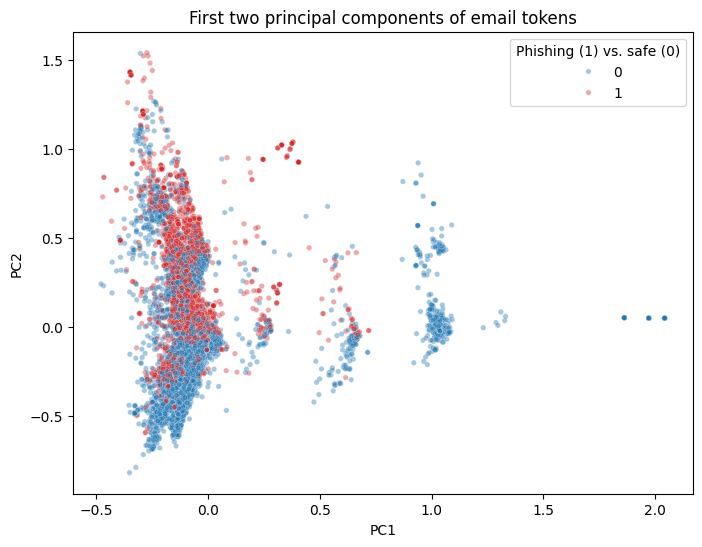

PC1 - most negative loadings:
please    -0.109
would     -0.090
like      -0.090
get       -0.068
message   -0.049
enron     -0.047
email     -0.046
know      -0.043
call      -0.043
dear      -0.041 

PC1 - most positive loadings:
date         0.674
url:         0.367
start        0.287
hour         0.261
hourahead    0.256
ancillary    0.195
schedules    0.194
required     0.063
schedule     0.063
failure      0.062 

PC2 - most negative loadings:
please       -0.199
message      -0.149
attached     -0.134
call         -0.134
enron        -0.114
conference   -0.101
original     -0.094
papers       -0.087
university   -0.082
see          -0.057 

PC2 - most positive loadings:
new          0.452
like         0.414
would        0.319
get          0.316
hello        0.146
offer        0.137
software     0.129
one          0.120
available    0.084
online       0.082 

Train R2: 0.7651
Test R2:  0.6718
Variance retained: 0.9998
Rank of X_train: 2641 (out of 2711 columns)


In [1]:
# ============================================================
# Phase 2: AI-assisted solution
# ============================================================

import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

!git clone https://github.com/willhk10-uva/A05-pca

# ============================================================
# Q1. Token frequency distribution
# ============================================================

with open('A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

counts = np.array(list(token_count.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram of how often tokens occur
axes[0].hist(counts, bins=100)
axes[0].set_xlabel('Number of occurrences')
axes[0].set_ylabel('Number of tokens')
axes[0].set_title('Token frequency histogram')

# Same data on log scales so the shape is visible
axes[1].hist(counts, bins=np.logspace(0, np.log10(counts.max()), 50))
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Number of occurrences (log)')
axes[1].set_ylabel('Number of tokens (log)')
axes[1].set_title('Log-log histogram')

plt.tight_layout()
plt.show()

top100_share = sum(c for _, c in token_count.most_common(100)) / len(all_tokens)

print(f"Total tokens:              {len(all_tokens):,}")
print(f"Distinct tokens:           {len(counts):,}")
print(f"Tokens appearing once:     {(counts == 1).sum():,} ({(counts == 1).mean():.1%} of distinct)")
print(f"Share held by top 100:     {top100_share:.1%}")
print("Top 10:", token_freq[:10])

# Q1 answer:
# The distribution of token counts is extremely right-skewed. In the linear
# histogram, almost all of the ~48,700 distinct tokens fall in the first bin
# (fewer than ~14 occurrences), with a long, nearly invisible tail out to 1,365
# (the most common token, "new"). The log-log plot shows the shape more clearly:
# 29,404 tokens, about 60% of the distinct tokens, appear only once, and the
# number of tokens drops steadily as frequency increases. Only a handful of
# tokens appear 1,000+ times.
#
# The roughly straight line on log-log axes suggests a power law (Zipf's law):
# most of the vocabulary is made up of very rare words. Even so, the most common
# words don't dominate the text as much as you might expect, since the top 100
# tokens only make up about 17% of all 276,949 token occurrences. That's probably
# because the very common words like "the" were already removed.

# ============================================================
# Q2. Linear regression on the one-hot-encoded tokens
# ============================================================

df = pd.read_parquet('A05-pca/data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop(columns='Email Type')

# 1. 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=125
)

# 2. Linear regression
reg = LinearRegression().fit(X_train, y_train)

print(f"Train R2: {reg.score(X_train, y_train):.4f}")
print(f"Test R2:  {reg.score(X_test, y_test):.4f}")

# 3. Largest coefficients in absolute value
coefs = pd.DataFrame({
    'token': X.columns,
    'coef': reg.coef_,
    'n_emails': X_train.sum().values,
})
coefs['abs_coef'] = coefs['coef'].abs()
top = coefs.sort_values('abs_coef', ascending=False)
print(top.head(20))

# Q2 answer:
# R^2: The regression gets an R^2 of about 0.766 on the training set and 0.670
# on the test set. So the token features explain a good amount of the variation
# in whether an email is a scam, but there's a noticeable drop from train to
# test, which means the model is overfitting somewhat with 2,711 predictors.
#
# Most influential words: The tokens with the largest coefficients in absolute
# value are "localized", "aging", "thermal", "helvetica," and "erectile"
# (positive coefficients, so they push the prediction toward phishing) and
# "background-image:", "intervention", "burning", "april's" and "cnet"
# (negative coefficients, so they push toward safe). Since y is 0/1, each
# coefficient is roughly the change in the predicted probability of phishing
# when that word appears, holding the other words fixed.
#
# One caveat: several of the top words only show up in a small number of emails
# (see the n_emails column), and a lot of the tokens are correlated with each
# other, so the exact size of these coefficients isn't very stable. They show
# which words the model leans on, but I wouldn't read too much into the
# specific numbers.

# ============================================================
# Q3. PCA with two components
# ============================================================

# PCA with two components on the token matrix (outcome excluded)
pca = PCA(n_components=2)
Z = pca.fit_transform(X)

pcs = pd.DataFrame(Z, columns=['PC1', 'PC2'])
pcs['Email Type'] = y.values

print("Variance explained:", pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pcs, x='PC1', y='PC2', hue='Email Type',
                alpha=0.4, s=15, palette={0: 'tab:blue', 1: 'tab:red'})
plt.title('First two principal components of email tokens')
plt.legend(title='Phishing (1) vs. safe (0)')
plt.show()

# Which words load most heavily on each component
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=['PC1', 'PC2'])

for pc in ['PC1', 'PC2']:
    ordered = loadings[pc].sort_values()
    print(f"{pc} - most negative loadings:")
    print(ordered.head(10).round(3).to_string(), "\n")
    print(f"{pc} - most positive loadings:")
    print(ordered.tail(10)[::-1].round(3).to_string(), "\n")

# Q3 answer:
# The two components explain very little of the variance: 1.1% and 0.9%, about
# 2% total. That's expected with 2,711 sparse 0/1 columns, so most of the
# information is in other directions.
#
# There is still some structure, though. Most emails sit in one dense cloud near
# PC1 ~ 0. Along PC2, safe emails concentrate at the bottom and phishing emails
# spread higher, so higher PC2 scores lean toward scams. The loadings printed
# above show that PC2 contrasts business-email words ("please", "message",
# "attached", "enron", "conference") with sales-style words ("hello", "offer",
# "software", "new").
#
# Separate clusters at PC1 ~ 0.6, 1.0 and 2.0 are almost entirely safe emails.
# These are automated Enron energy-scheduling messages ("hourahead",
# "schedules", "ancillary", "url:"), which load heavily on PC1.
#
# The classes overlap a lot in the main cloud, so two components can't separate
# them well, but PC2 carries some signal.

# ============================================================
# Q4. Linear regression on the first 2,610 principal components
# ============================================================

pca = PCA(n_components=2610).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)

reg_pca = LinearRegression().fit(Z_train, y_train)

print(f"Train R2: {reg_pca.score(Z_train, y_train):.4f}")
print(f"Test R2:  {reg_pca.score(Z_test, y_test):.4f}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.4f}")

# How many truly independent directions the token matrix has
print(f"Rank of X_train: {np.linalg.matrix_rank(X_train.values.astype(float))} "
      f"(out of {X_train.shape[1]} columns)")

# Q4 answer:
# When running the regression on the first 2,610 principal components, we get
# an R^2 of 0.765 on training and 0.672 on test. That's basically the same as
# the regression on the original tokens, which had 0.766 on training and 0.670
# on test.
#
# This isn't a full rotation of the data, since we dropped about 100 of the
# 2,711 possible directions. But the rank of X_train is only  2,641,
# meaning a lot of the token columns are (close to) linear combinations of
# other columns. Because of that, the 2,610 components still keep about 99.98%
# of the variance, and the components we dropped carry almost nothing. So the
# regression has almost the same information as before, and the predictions
# barely change.
#
# There's still a sizeable gap between the training and test R^2, so the model
# overfits about as much as it did before. Keeping nearly all of the components
# doesn't really reduce the dimension, so to get an actual benefit from PCA we
# would probably need to keep a lot fewer components.

# ============================================================
# Q5. Advantage of using principal components
# ============================================================

# Q5 answer:
# The original token columns overlap quite a bit. Lots of words tend to show up
# together, so many of the columns are highly correlated (and a few might be
# near copies of each other). When that happens the regression coefficients
# become unstable: the model can't tell which of the two words should get the
# credit, so it freaks out and the coefficients swing around. Principal
# components don't have this problem because they're fully uncorrelated, so
# each one adds something new.
#
# They're also sorted by how much of the variance in the token data (X) they
# explain, so you can keep the first few and drop the rest. Using fewer
# predictors relative to the number of emails gives more stable estimates and a
# model that's less likely to overfit. One catch is that PCA never looks at
# whether an email is a scam, so the components with the most variance aren't
# guaranteed to be the most useful for predicting phishing, and the ones you
# drop aren't guaranteed to be just noise.
#
# In this example we kept 2,610 components, which is basically all of them, so
# the R^2 barely changed. With far fewer components, the model would be simpler
# and might overfit less, but it could also underfit and lose accuracy.

### *Reflection on AI assistance
In your own words without generative AI.

The main things that I saw are that I missed quite a lot of things. There were a total of 10 proposed changes, of which I accepted 6 with 3 modifications. I can't believe that I missed the written answer on question 2, I definitely should have checked my work more throughly before moving onto Phase 2. I feel as though I had an answer for it and then deleted it because I wanted to reword it, and then ended up forgetting to do so. Oops :(. I did unfortunately make some typos, which AI is good at catching, and there was a real conceptual error that I missed on question 5 with the PCA. All in all I think the AI check found some actual real issues that were important to go back and solve, and I'm glad I went through and checked through the entirety of the assignment with AI because I understand the PCA better now. I did review the AI-generated output and found some glaring issues, mainly that it had placeholders and expected me to go back through and input things from the actual code which I did not expect. I thought that it would give the answers in full, so I had to go back through and correct that. I don't think there are any remaining concerns.